# Plot options: LOG or LINEAR

Edit `COLOR_SCALE` in the code cell immediately below: **`'log'`** or **`'linear'`**.
Choose **`'nearest'`** or **`'bilinear'`** for `INTERPOLATION`, then **Run All**.
These settings apply to pupil maps and the MP4; `COLOR_SCALE` also controls the flux diagnostic Y axes.

Notebook: **analyse_fiber_focus_scans.ipynb - display controls at top**.


In [1]:
# PLOT OPTIONS - edit these two lines, then Run All.
COLOR_SCALE = 'log'          # 'log' or 'linear'
INTERPOLATION = 'nearest'   # 'nearest' or 'bilinear'

if COLOR_SCALE not in {'log', 'linear'}:
    raise ValueError("COLOR_SCALE must be 'log' or 'linear'.")
if INTERPOLATION not in {'nearest', 'bilinear'}:
    raise ValueError("INTERPOLATION must be 'nearest' or 'bilinear'.")
print(f'Plot settings: Voltage | {COLOR_SCALE} scale | {INTERPOLATION} interpolation')


Plot settings: Voltage | log scale | nearest interpolation


# Fiber focus: spatial and spectral pupil maps

Analyse the FITS cubes produced by the neighbouring `fiber_focus_scans.py`.

1. **Integrated pupil:** a 2D X/Y map at every Z, summed over all stored detector columns.
2. **Spectral pupils:** eight 50 nm maps at every Z, from **1300-1350** through **1650-1700 nm**.
3. **MP4 animation:** the eight spectral pupils advancing through Z with a fixed colour scale.
4. **Diagnostics:** calibration and coverage, a spectrum at the brightest measured position, and a focus curve.

**The saved outputs below are a synthetic preview, not measured results.** To analyse observations,
set `USE_DEMO_DATA = False` below and run all cells. The notebook discovers cubes in the
configured acquisition output location; optionally set `DATA_PATH` to select a specific file. A missing real file raises an error; it never switches to demo silently.

Dependencies: Python 3.10+, NumPy, Matplotlib, Astropy and a Jupyter kernel. The analysis does not
import the acquisition script, connect to hardware, alter source data. The optional animation export writes one derived MP4.

**Plot appearance:** set `INTERPOLATION = 'nearest'` or `'bilinear'` in the dedicated **Plot options** cell at the very top,
then run all cells. Pupil maps and MP4 frames use **CMasher Voltage**. Nearest shows sampled cells;
bilinear smooths their appearance. Set `COLOR_SCALE = 'log'` (default) or `'linear'` in that
cell. This controls pupil colourbars, MP4 frames and the flux diagnostic Y axes; X/Y/Z coordinates
and the wavelength-calibration plot stay linear. Scaling and interpolation do not change calculated flux.
In log mode, nonpositive flux is hidden from plots rather than replaced by an artificial positive value.


In [2]:
from pathlib import Path
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm, ListedColormap
from astropy.io import fits

# USER SETTINGS ---------------------------------------------------------------
USE_DEMO_DATA = True  # False analyses observations; True generates the saved synthetic preview
OUTPUT_ROOT = Path('/home/scexao/glint/glintdata/alignment_scan')  # instrument.json output_root
SCAN_DATE = None  # None searches every date; or e.g. '20261116'
DATA_PATH = None  # None selects newest discovered cube when USE_DEMO_DATA=False; or an explicit FITS path
CALIBRATION_PATH = None  # None uses the embedded snapshot; or point to wavelength_solution.json
Z_INDICES = None  # None plots EVERY Z; e.g. [0, 2] selects two planes
BIN_EDGES_NM = np.arange(1300.0, 1700.0 + 50.0, 50.0)
PANELS_PER_PAGE = 6  # integrated maps are paginated for long scans
EXPORT_MP4 = True  # save and embed the spectral-pupil animation
MP4_PATH = None  # None: beside real cube, or beside this notebook in demo mode
MP4_FPS = 8
MP4_SECONDS_PER_Z = 1.25  # each Z plane is held; no interpolation between measurements

plt.rcParams.update({'figure.dpi': 115, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'})



In [3]:
# Official CMasher Voltage RGB table, embedded for offline use (no CMasher dependency).
# Source: https://github.com/1313e/CMasher/blob/master/src/cmasher/colormaps/voltage/voltage_norm.txt
# Copyright (c) 2019-2021 Ellert van der Velden. BSD-3-Clause; notice at end of notebook.
VOLTAGE_RGB = np.array([
 [
  0.0,
  0.0,
  0.0
 ],
 [
  0.00031246,
  0.00020111,
  0.00025627
 ],
 [
  0.00112231,
  0.00068156,
  0.00090515
 ],
 [
  0.00239896,
  0.0013819,
  0.00190777
 ],
 [
  0.00413895,
  0.00227217,
  0.00325294
 ],
 [
  0.00634537,
  0.00333163,
  0.0049374
 ],
 [
  0.00902409,
  0.00454421,
  0.00696179
 ],
 [
  0.01218267,
  0.00589658,
  0.00932927
 ],
 [
  0.01582945,
  0.00737731,
  0.01204468
 ],
 [
  0.01997325,
  0.00897635,
  0.01511413
 ],
 [
  0.0246234,
  0.01068456,
  0.01854486
 ],
 [
  0.02978979,
  0.01249342,
  0.02234523
 ],
 [
  0.03548237,
  0.01439508,
  0.02652436
 ],
 [
  0.04167864,
  0.01638226,
  0.03109205
 ],
 [
  0.04793582,
  0.01844783,
  0.03605917
 ],
 [
  0.05415654,
  0.0205849,
  0.04141397
 ],
 [
  0.06034557,
  0.02278724,
  0.04682409
 ],
 [
  0.06650808,
  0.02504817,
  0.05222469
 ],
 [
  0.07264753,
  0.02736176,
  0.05762094
 ],
 [
  0.07876737,
  0.0297219,
  0.06301786
 ],
 [
  0.08487075,
  0.03212247,
  0.06842017
 ],
 [
  0.09095989,
  0.03455789,
  0.07383177
 ],
 [
  0.09703748,
  0.03702196,
  0.07925694
 ],
 [
  0.10310516,
  0.03950925,
  0.08469904
 ],
 [
  0.1091649,
  0.04197056,
  0.09016173
 ],
 [
  0.11521837,
  0.04434927,
  0.09564841
 ],
 [
  0.1212665,
  0.04665645,
  0.10116184
 ],
 [
  0.12731142,
  0.04889222,
  0.10670591
 ],
 [
  0.13335353,
  0.05105807,
  0.11228296
 ],
 [
  0.13939383,
  0.05315462,
  0.1178959
 ],
 [
  0.14543374,
  0.05518173,
  0.12354815
 ],
 [
  0.15147372,
  0.05714,
  0.12924223
 ],
 [
  0.15751435,
  0.05902971,
  0.13498083
 ],
 [
  0.16355626,
  0.0608508,
  0.14076677
 ],
 [
  0.1696,
  0.0626031,
  0.14660287
 ],
 [
  0.17564611,
  0.06428622,
  0.15249203
 ],
 [
  0.181695,
  0.06589972,
  0.15843708
 ],
 [
  0.18774677,
  0.0674433,
  0.16444064
 ],
 [
  0.19380164,
  0.06891635,
  0.17050552
 ],
 [
  0.19985972,
  0.07031815,
  0.17663454
 ],
 [
  0.20592106,
  0.07164791,
  0.18283055
 ],
 [
  0.21198587,
  0.07290437,
  0.18909673
 ],
 [
  0.21805388,
  0.07408672,
  0.19543581
 ],
 [
  0.22412484,
  0.07519393,
  0.20185063
 ],
 [
  0.23019844,
  0.07622486,
  0.20834412
 ],
 [
  0.23627427,
  0.07717828,
  0.21491919
 ],
 [
  0.24235253,
  0.07805177,
  0.22157986
 ],
 [
  0.24843203,
  0.07884488,
  0.22832824
 ],
 [
  0.25451222,
  0.07955585,
  0.2351676
 ],
 [
  0.26059284,
  0.08018223,
  0.24210183
 ],
 [
  0.26667241,
  0.08072334,
  0.24913312
 ],
 [
  0.27275065,
  0.08117617,
  0.25626577
 ],
 [
  0.278826,
  0.08153962,
  0.26350227
 ],
 [
  0.28489723,
  0.08181183,
  0.27084577
 ],
 [
  0.29096358,
  0.08198959,
  0.27830065
 ],
 [
  0.29702302,
  0.08207192,
  0.28586912
 ],
 [
  0.30307395,
  0.08205667,
  0.29355451
 ],
 [
  0.30911459,
  0.08194169,
  0.30136007
 ],
 [
  0.31514295,
  0.081725,
  0.3092889
 ],
 [
  0.3211568,
  0.08140474,
  0.31734395
 ],
 [
  0.32715368,
  0.0809793,
  0.32552795
 ],
 [
  0.33313088,
  0.08044737,
  0.33384339
 ],
 [
  0.33908542,
  0.07980801,
  0.34229246
 ],
 [
  0.34501425,
  0.07906022,
  0.35087753
 ],
 [
  0.35091402,
  0.07820361,
  0.35960048
 ],
 [
  0.35678059,
  0.07724,
  0.36846149
 ],
 [
  0.36261051,
  0.07616906,
  0.3774629
 ],
 [
  0.36839888,
  0.07499522,
  0.38660322
 ],
 [
  0.37414151,
  0.07372084,
  0.39588331
 ],
 [
  0.37983327,
  0.07235224,
  0.40530123
 ],
 [
  0.38546889,
  0.07089703,
  0.41485479
 ],
 [
  0.39104291,
  0.06936492,
  0.42454112
 ],
 [
  0.39654956,
  0.06776848,
  0.43435623
 ],
 [
  0.40198284,
  0.06612364,
  0.44429498
 ],
 [
  0.40733651,
  0.06445017,
  0.45435099
 ],
 [
  0.41260418,
  0.06277218,
  0.46451665
 ],
 [
  0.41777939,
  0.06111855,
  0.47478307
 ],
 [
  0.42285565,
  0.05952328,
  0.48514013
 ],
 [
  0.42782659,
  0.05802486,
  0.49557717
 ],
 [
  0.43268582,
  0.05666848,
  0.50608125
 ],
 [
  0.43742726,
  0.05550325,
  0.516639
 ],
 [
  0.44204513,
  0.05458165,
  0.52723648
 ],
 [
  0.44653397,
  0.05395922,
  0.53785824
 ],
 [
  0.45088883,
  0.05369027,
  0.54848918
 ],
 [
  0.45510522,
  0.05382701,
  0.55911317
 ],
 [
  0.45917927,
  0.05441507,
  0.5697145
 ],
 [
  0.46310766,
  0.05549137,
  0.58027742
 ],
 [
  0.46688772,
  0.05708145,
  0.59078658
 ],
 [
  0.47051741,
  0.05919812,
  0.60122724
 ],
 [
  0.4739953,
  0.06184117,
  0.61158545
 ],
 [
  0.47732056,
  0.06499851,
  0.62184802
 ],
 [
  0.48049291,
  0.06864775,
  0.63200298
 ],
 [
  0.4835126,
  0.07275889,
  0.64203927
 ],
 [
  0.48638035,
  0.07729672,
  0.65194705
 ],
 [
  0.4890973,
  0.08222323,
  0.66171766
 ],
 [
  0.49166496,
  0.08749968,
  0.67134353
 ],
 [
  0.49408514,
  0.09308809,
  0.68081816
 ],
 [
  0.49635987,
  0.09895222,
  0.69013638
 ],
 [
  0.49849156,
  0.10505847,
  0.69929343
 ],
 [
  0.50048254,
  0.1113759,
  0.70828623
 ],
 [
  0.50233543,
  0.11787666,
  0.71711216
 ],
 [
  0.50405303,
  0.12453572,
  0.72576907
 ],
 [
  0.50563797,
  0.13133085,
  0.73425617
 ],
 [
  0.50709307,
  0.13824237,
  0.74257292
 ],
 [
  0.50842113,
  0.14525291,
  0.75071938
 ],
 [
  0.50962496,
  0.1523472,
  0.75869606
 ],
 [
  0.51070736,
  0.15951182,
  0.76650391
 ],
 [
  0.5116711,
  0.16673502,
  0.77414424
 ],
 [
  0.51251888,
  0.17400648,
  0.78161867
 ],
 [
  0.51325338,
  0.18131718,
  0.78892907
 ],
 [
  0.51387721,
  0.18865921,
  0.79607754
 ],
 [
  0.51439291,
  0.19602566,
  0.80306633
 ],
 [
  0.51480296,
  0.20341048,
  0.80989783
 ],
 [
  0.51510977,
  0.21080838,
  0.81657454
 ],
 [
  0.5153157,
  0.21821474,
  0.82309901
 ],
 [
  0.51542301,
  0.22562551,
  0.82947387
 ],
 [
  0.51543415,
  0.23303699,
  0.83570159
 ],
 [
  0.51535107,
  0.24044625,
  0.84178498
 ],
 [
  0.51517586,
  0.24785059,
  0.84772665
 ],
 [
  0.51491068,
  0.25524758,
  0.85352914
 ],
 [
  0.51455754,
  0.26263517,
  0.85919502
 ],
 [
  0.51411822,
  0.2700117,
  0.86472687
 ],
 [
  0.51359482,
  0.27737548,
  0.87012706
 ],
 [
  0.51298904,
  0.28472528,
  0.87539803
 ],
 [
  0.51230269,
  0.29205997,
  0.88054209
 ],
 [
  0.51153768,
  0.29937847,
  0.88556143
 ],
 [
  0.51069552,
  0.30668011,
  0.89045825
 ],
 [
  0.50977821,
  0.31396399,
  0.89523452
 ],
 [
  0.50878714,
  0.32122973,
  0.89989228
 ],
 [
  0.5077243,
  0.32847663,
  0.9044333
 ],
 [
  0.50659106,
  0.33570449,
  0.9088594
 ],
 [
  0.50538936,
  0.3429128,
  0.91317217
 ],
 [
  0.50412065,
  0.35010144,
  0.91737317
 ],
 [
  0.50278681,
  0.3572701,
  0.92146382
 ],
 [
  0.50138942,
  0.3644187,
  0.92544542
 ],
 [
  0.4999303,
  0.37154707,
  0.92931919
 ],
 [
  0.49841121,
  0.37865516,
  0.93308619
 ],
 [
  0.49683398,
  0.38574291,
  0.9367474
 ],
 [
  0.49520056,
  0.39281027,
  0.94030367
 ],
 [
  0.49351285,
  0.39985726,
  0.94375573
 ],
 [
  0.49177299,
  0.40688384,
  0.9471042
 ],
 [
  0.4899831,
  0.41389003,
  0.95034958
 ],
 [
  0.48814547,
  0.42087583,
  0.95349225
 ],
 [
  0.48626251,
  0.42784124,
  0.95653246
 ],
 [
  0.4843368,
  0.43478625,
  0.95947037
 ],
 [
  0.48237102,
  0.44171086,
  0.96230598
 ],
 [
  0.48036816,
  0.44861499,
  0.96503923
 ],
 [
  0.47833124,
  0.45549864,
  0.96766989
 ],
 [
  0.47626373,
  0.46236169,
  0.97019765
 ],
 [
  0.47416915,
  0.46920405,
  0.97262205
 ],
 [
  0.47205144,
  0.47602558,
  0.97494257
 ],
 [
  0.46991481,
  0.48282608,
  0.97715854
 ],
 [
  0.46776372,
  0.48960538,
  0.97926917
 ],
 [
  0.46560321,
  0.49636315,
  0.98127364
 ],
 [
  0.46343842,
  0.50309916,
  0.98317091
 ],
 [
  0.46127529,
  0.50981294,
  0.98496001
 ],
 [
  0.45911981,
  0.51650417,
  0.98663968
 ],
 [
  0.45697893,
  0.52317226,
  0.98820879
 ],
 [
  0.4548597,
  0.52981674,
  0.98966594
 ],
 [
  0.45277011,
  0.53643692,
  0.99100984
 ],
 [
  0.45071855,
  0.5430321,
  0.99223903
 ],
 [
  0.44871406,
  0.54960153,
  0.99335202
 ],
 [
  0.44676665,
  0.55614422,
  0.99434747
 ],
 [
  0.44488639,
  0.56265938,
  0.99522365
 ],
 [
  0.44308487,
  0.56914577,
  0.99597931
 ],
 [
  0.44137397,
  0.57560228,
  0.99661298
 ],
 [
  0.4397662,
  0.5820277,
  0.99712316
 ],
 [
  0.43827527,
  0.58842056,
  0.99750876
 ],
 [
  0.43691538,
  0.59477937,
  0.99776866
 ],
 [
  0.43570118,
  0.60110264,
  0.99790168
 ],
 [
  0.43464843,
  0.60738857,
  0.99790727
 ],
 [
  0.43377328,
  0.61363535,
  0.99778493
 ],
 [
  0.43309232,
  0.61984106,
  0.99753448
 ],
 [
  0.43262243,
  0.62600374,
  0.99715601
 ],
 [
  0.43238086,
  0.63212125,
  0.99665016
 ],
 [
  0.43238487,
  0.63819141,
  0.99601806
 ],
 [
  0.43265151,
  0.64421198,
  0.9952613
 ],
 [
  0.43319741,
  0.65018068,
  0.9943821
 ],
 [
  0.43403856,
  0.65609523,
  0.99338327
 ],
 [
  0.43519,
  0.66195334,
  0.99226837
 ],
 [
  0.43666556,
  0.66775277,
  0.99104163
 ],
 [
  0.43847758,
  0.67349134,
  0.98970814
 ],
 [
  0.44063658,
  0.67916699,
  0.98827371
 ],
 [
  0.44315105,
  0.6847778,
  0.98674494
 ],
 [
  0.4460272,
  0.69032206,
  0.98512916
 ],
 [
  0.44926876,
  0.69579827,
  0.98343447
 ],
 [
  0.45287691,
  0.70120519,
  0.98166958
 ],
 [
  0.45685017,
  0.70654187,
  0.97984398
 ],
 [
  0.46118441,
  0.71180769,
  0.97796752
 ],
 [
  0.4658729,
  0.7170024,
  0.97605029
 ],
 [
  0.47090655,
  0.7221261,
  0.97410266
 ],
 [
  0.47627396,
  0.7271792,
  0.97213557
 ],
 [
  0.48196178,
  0.73216253,
  0.97015966
 ],
 [
  0.48795513,
  0.73707731,
  0.96818479
 ],
 [
  0.49423737,
  0.74192493,
  0.96622226
 ],
 [
  0.50079146,
  0.74670729,
  0.96428075
 ],
 [
  0.5075989,
  0.7514264,
  0.96237083
 ],
 [
  0.51464171,
  0.75608463,
  0.96050004
 ],
 [
  0.52190077,
  0.76068447,
  0.95867798
 ],
 [
  0.52935797,
  0.76522862,
  0.95691155
 ],
 [
  0.53699541,
  0.76971992,
  0.95520746
 ],
 [
  0.54479559,
  0.77416124,
  0.95357212
 ],
 [
  0.55274175,
  0.77855558,
  0.95201122
 ],
 [
  0.56081796,
  0.78290593,
  0.95052976
 ],
 [
  0.56900925,
  0.7872153,
  0.94913199
 ],
 [
  0.57730169,
  0.79148666,
  0.94782152
 ],
 [
  0.58568238,
  0.79572294,
  0.94660125
 ],
 [
  0.59413953,
  0.79992699,
  0.94547349
 ],
 [
  0.60266194,
  0.80410164,
  0.94444057
 ],
 [
  0.61123873,
  0.80824967,
  0.94350526
 ],
 [
  0.61986233,
  0.81237355,
  0.9426666
 ],
 [
  0.6285226,
  0.81647602,
  0.94192797
 ],
 [
  0.63721403,
  0.82055927,
  0.94128733
 ],
 [
  0.64592748,
  0.82462593,
  0.9407481
 ],
 [
  0.65465898,
  0.82867796,
  0.9403077
 ],
 [
  0.66340275,
  0.83271754,
  0.93996652
 ],
 [
  0.67215238,
  0.83674693,
  0.9397262
 ],
 [
  0.68090506,
  0.84076785,
  0.93958452
 ],
 [
  0.68965684,
  0.84478217,
  0.93954112
 ],
 [
  0.69840426,
  0.84879167,
  0.93959548
 ],
 [
  0.70714432,
  0.85279803,
  0.93974694
 ],
 [
  0.71587442,
  0.85680284,
  0.93999469
 ],
 [
  0.72459236,
  0.86080761,
  0.94033785
 ],
 [
  0.73329625,
  0.86481377,
  0.9407754
 ],
 [
  0.74198452,
  0.86882267,
  0.9413063
 ],
 [
  0.75065588,
  0.87283558,
  0.94192942
 ],
 [
  0.75930745,
  0.87685409,
  0.94264556
 ],
 [
  0.7679399,
  0.88087904,
  0.94345188
 ],
 [
  0.77655261,
  0.88491151,
  0.94434714
 ],
 [
  0.78514349,
  0.88895287,
  0.9453318
 ],
 [
  0.79371246,
  0.89300405,
  0.94640437
 ],
 [
  0.80226011,
  0.89706581,
  0.94756279
 ],
 [
  0.81078346,
  0.90113969,
  0.94880881
 ],
 [
  0.81928545,
  0.90522587,
  0.95013824
 ],
 [
  0.82776227,
  0.90932608,
  0.95155384
 ],
 [
  0.83621702,
  0.91344039,
  0.95305152
 ],
 [
  0.84464705,
  0.91757024,
  0.954633
 ],
 [
  0.85305358,
  0.92171613,
  0.95629628
 ],
 [
  0.86143702,
  0.92587871,
  0.9580402
 ],
 [
  0.86979478,
  0.9300594,
  0.95986662
 ],
 [
  0.87812911,
  0.93425838,
  0.96177275
 ],
 [
  0.88643972,
  0.93847643,
  0.96375834
 ],
 [
  0.89472555,
  0.94271457,
  0.96582393
 ],
 [
  0.9029863,
  0.94697357,
  0.96796934
 ],
 [
  0.91122262,
  0.95125397,
  0.9701936
 ],
 [
  0.91943415,
  0.95555654,
  0.97249673
 ],
 [
  0.92762042,
  0.95988208,
  0.97487889
 ],
 [
  0.93578091,
  0.96423141,
  0.97734034
 ],
 [
  0.94391496,
  0.96860538,
  0.97988153
 ],
 [
  0.95202139,
  0.97300497,
  0.98250342
 ],
 [
  0.96009954,
  0.97743102,
  0.98520655
 ],
 [
  0.96814816,
  0.98188453,
  0.98799202
 ],
 [
  0.97616544,
  0.98636667,
  0.99086151
 ],
 [
  0.98414897,
  0.99087878,
  0.99381721
 ],
 [
  0.99209543,
  0.99542251,
  0.99686206
 ],
 [
  1.0,
  1.0,
  1.0
 ]
], dtype=float)
CMAP = ListedColormap(VOLTAGE_RGB, name='cmr.voltage')
CMAP.set_bad('#d9dfe5')  # invalid points are grey in nearest and bilinear modes


## Where the acquisition script saves cubes

With the current `glint_alignment_refactor/config/instrument.json`, the exact filename pattern is:

`/home/scexao/glint/glintdata/alignment_scan/YYYYMMDD/Fiber_scan_focus/fiber_focus_N.fits`

For example, a run on 16 November 2026 starts at
`/home/scexao/glint/glintdata/alignment_scan/20261116/Fiber_scan_focus/fiber_focus_1.fits`
(if that run number is unused). The acquisition script uses its local run date, and N increments within
each date's folder. It saves a JSON sidecar and PNG alongside the FITS cube. This location follows
`output_root` in the instrument configuration passed to the acquisition script. If you used a custom
configuration, or copied data to Windows, update `OUTPUT_ROOT` or give the copied cube's `DATA_PATH`.

The discovery cell lists matching cubes. With `USE_DEMO_DATA=False`, `DATA_PATH=None` selects the newest
by file modification time; an explicit `DATA_PATH` takes precedence. No available data causes a clear
error in observation mode. Demo mode never opens an observation file.


In [4]:
date_folder = str(SCAN_DATE) if SCAN_DATE is not None else '[0-9]' * 8
available_cubes = sorted(OUTPUT_ROOT.expanduser().glob(f'{date_folder}/Fiber_scan_focus/fiber_focus_*.fits'),
                         key=lambda path: (path.stat().st_mtime_ns, str(path)))
print('Acquisition output pattern:', OUTPUT_ROOT / 'YYYYMMDD' / 'Fiber_scan_focus' / 'fiber_focus_N.fits')
print(f'Found {len(available_cubes)} cube(s). Newest up to 20 shown:')
for path in available_cubes[-20:]:
    print(' ', path)
selected_data_path = None
if USE_DEMO_DATA:
    print('SYNTHETIC PREVIEW MODE. Set USE_DEMO_DATA=False to load an observation.')
elif DATA_PATH is not None:
    selected_data_path = Path(DATA_PATH).expanduser()
    if not selected_data_path.is_file():
        raise FileNotFoundError(f'Selected cube not found: {selected_data_path}')
elif available_cubes:
    selected_data_path = available_cubes[-1]
else:
    raise FileNotFoundError(f'No fiber_focus_*.fits below {OUTPUT_ROOT}. Set OUTPUT_ROOT or DATA_PATH to the data location.')
if selected_data_path is not None:
    print('Selected observation:', selected_data_path)


Acquisition output pattern: \home\scexao\glint\glintdata\alignment_scan\YYYYMMDD\Fiber_scan_focus\fiber_focus_N.fits
Found 0 cube(s). Newest up to 20 shown:
SYNTHETIC PREVIEW MODE. Set USE_DEMO_DATA=False to load an observation.


## Calibration at the fiber trace

The supplied `calibration_output/wavelength_solution.json` (schema 2, created 2026-09-08) contains
cross-channel trace fits `detector_x(wavelength, detector_y)`. There is no directly measured port-8
channel in that file. We evaluate each fitted monochromatic trace at the **centre of the saved box rows**
and linearly interpolate between its wavelength knots. This is a **spatially inferred port-8 calibration**,
not a direct calibration of that fiber. It assumes the fiber follows the same detector dispersion surface.

The normalization is reproduced from `pipeline/glint_wavecal.py::fit_trace_model`:
`yn = (y - mean(all channel centres)) / max(ptp(all channel centres)/2, 1)`.
Wavelength extrapolation and extrapolation beyond the supporting detector rows are rejected.
The numerical source coefficients and provenance are embedded below for portability. Set
`CALIBRATION_PATH` to load an updated full solution instead. No calibration file is copied or edited.
The wavelength convention follows the calibration filenames, without air/vacuum conversion.


In [5]:
EMBEDDED_CALIBRATION = json.loads(r'''
{
  "source_file": "C:\\Users\\mcol0021\\OneDrive - The University of Sydney (Staff)\\Desktop\\GLINT_test reports\\GLINT_APAPANE_wavelength_calibration\\calibration_output\\wavelength_solution.json",
  "source_sha256": "380c29d43c923593801cf4c8acf75733c88a094359e28a27145222070b6f147e",
  "created_utc": "2026-09-08T05:22:42.893810+00:00",
  "schema_version": 2,
  "trace_models": [
    {
      "wavelength_nm": 1200.0,
      "coefficients_for_normalized_y_ascending_power": [
        110.72207128729045,
        -2.736150158588414,
        -5.787724401628924
      ],
      "rms_pixel": 0.22723745857337516,
      "support_channel_ids": [
        "phot_1",
        "phot_2",
        "phot_3",
        "n1_11_31_ft1",
        "n1_11_31_ft2",
        "n2_11_20_ft1",
        "n2_11_20_ft2",
        "n3_20_31_ft1",
        "n3_20_31_ft2"
      ]
    },
    {
      "wavelength_nm": 1250.0,
      "coefficients_for_normalized_y_ascending_power": [
        136.2605656129342,
        -2.8499297816329614,
        -5.496905001725147
      ],
      "rms_pixel": 0.17221116103738499,
      "support_channel_ids": [
        "phot_1",
        "phot_2",
        "phot_3",
        "n1_11_31_ft1",
        "n1_11_31_ft2",
        "n2_11_20_ft1",
        "n2_11_20_ft2",
        "n3_20_31_ft1",
        "n3_20_31_ft2"
      ]
    },
    {
      "wavelength_nm": 1300.0,
      "coefficients_for_normalized_y_ascending_power": [
        157.9734578998678,
        -2.750759195219552,
        -5.072523492556756
      ],
      "rms_pixel": 0.1403854066272288,
      "support_channel_ids": [
        "phot_1",
        "phot_2",
        "phot_3",
        "n1_11_31_ft1",
        "n1_11_31_ft2",
        "n2_11_20_ft1",
        "n2_11_20_ft2",
        "n3_20_31_ft1",
        "n3_20_31_ft2"
      ]
    },
    {
      "wavelength_nm": 1350.0,
      "coefficients_for_normalized_y_ascending_power": [
        177.3940680253761,
        -2.739949497747996,
        -5.408767669263737
      ],
      "rms_pixel": 0.05539905117961564,
      "support_channel_ids": [
        "phot_1",
        "phot_2",
        "phot_3",
        "n1_11_31_ft1",
        "n1_11_31_ft2",
        "n2_11_20_ft1",
        "n2_11_20_ft2",
        "n3_20_31_ft1",
        "n3_20_31_ft2"
      ]
    },
    {
      "wavelength_nm": 1400.0,
      "coefficients_for_normalized_y_ascending_power": [
        194.1550960411336,
        -2.8150469488888588,
        -5.048542797952065
      ],
      "rms_pixel": 0.11225106721543762,
      "support_channel_ids": [
        "phot_1",
        "phot_2",
        "phot_3",
        "n1_11_31_ft1",
        "n1_11_31_ft2",
        "n2_11_20_ft1",
        "n2_11_20_ft2",
        "n3_20_31_ft1",
        "n3_20_31_ft2"
      ]
    },
    {
      "wavelength_nm": 1450.0,
      "coefficients_for_normalized_y_ascending_power": [
        209.2811008440594,
        -2.7789519097817794,
        -5.235754140637014
      ],
      "rms_pixel": 0.09995393915354084,
      "support_channel_ids": [
        "phot_1",
        "phot_2",
        "phot_3",
        "n1_11_31_ft1",
        "n1_11_31_ft2",
        "n2_11_20_ft1",
        "n2_11_20_ft2",
        "n3_20_31_ft1",
        "n3_20_31_ft2"
      ]
    },
    {
      "wavelength_nm": 1500.0,
      "coefficients_for_normalized_y_ascending_power": [
        222.65152419154893,
        -2.676626449540458,
        -5.113894101749004
      ],
      "rms_pixel": 0.04082303189581721,
      "support_channel_ids": [
        "phot_1",
        "phot_2",
        "phot_3",
        "n1_11_31_ft1",
        "n1_11_31_ft2",
        "n2_11_20_ft1",
        "n2_11_20_ft2",
        "n3_20_31_ft1",
        "n3_20_31_ft2"
      ]
    },
    {
      "wavelength_nm": 1550.0,
      "coefficients_for_normalized_y_ascending_power": [
        234.5747956825917,
        -2.664031942387192,
        -5.04497819535988
      ],
      "rms_pixel": 0.02676477131138072,
      "support_channel_ids": [
        "phot_1",
        "phot_2",
        "phot_3",
        "n1_11_31_ft1",
        "n1_11_31_ft2",
        "n2_11_20_ft1",
        "n2_11_20_ft2",
        "n3_20_31_ft1",
        "n3_20_31_ft2"
      ]
    },
    {
      "wavelength_nm": 1600.0,
      "coefficients_for_normalized_y_ascending_power": [
        245.48366490406644,
        -2.6219724556608943,
        -5.090748483992172
      ],
      "rms_pixel": 0.11822341147229093,
      "support_channel_ids": [
        "phot_1",
        "phot_2",
        "phot_3",
        "n1_11_31_ft1",
        "n1_11_31_ft2",
        "n2_11_20_ft1",
        "n2_11_20_ft2",
        "n3_20_31_ft1",
        "n3_20_31_ft2"
      ]
    },
    {
      "wavelength_nm": 1650.0,
      "coefficients_for_normalized_y_ascending_power": [
        255.0674543477981,
        -2.702844921992064,
        -5.131617958101788
      ],
      "rms_pixel": 0.07277331150191564,
      "support_channel_ids": [
        "phot_1",
        "phot_2",
        "phot_3",
        "n1_11_31_ft1",
        "n1_11_31_ft2",
        "n2_11_20_ft1",
        "n2_11_20_ft2",
        "n3_20_31_ft1",
        "n3_20_31_ft2"
      ]
    },
    {
      "wavelength_nm": 1700.0,
      "coefficients_for_normalized_y_ascending_power": [
        266.3825872729101,
        -2.6933287543329154,
        -5.024773570284092
      ],
      "rms_pixel": 0.039178177860414276,
      "support_channel_ids": [
        "phot_1",
        "phot_2",
        "phot_3",
        "n1_11_31_ft1",
        "n1_11_31_ft2",
        "n2_11_20_ft1",
        "n2_11_20_ft2",
        "n3_20_31_ft1",
        "n3_20_31_ft2"
      ]
    }
  ],
  "channels": {
    "phot_1": {
      "y_center_pixel": 242.5
    },
    "phot_2": {
      "y_center_pixel": 224.5
    },
    "phot_3": {
      "y_center_pixel": 205.5
    },
    "n1_11_31_ft1": {
      "y_center_pixel": 186.5
    },
    "n1_11_31": {
      "y_center_pixel": 168.5
    },
    "n1_11_31_ft2": {
      "y_center_pixel": 149.5
    },
    "n2_11_20_ft1": {
      "y_center_pixel": 130.5
    },
    "n2_11_20": {
      "y_center_pixel": 112.0
    },
    "n2_11_20_ft2": {
      "y_center_pixel": 93.5
    },
    "n3_20_31_ft1": {
      "y_center_pixel": 55.5
    },
    "n3_20_31": {
      "y_center_pixel": 37.5
    },
    "n3_20_31_ft2": {
      "y_center_pixel": 18.5
    }
  },
  "coordinate_conventions": {
    "detector_shape_yx": [
      256,
      320
    ],
    "x_pixel": "zero-indexed detector-column centre",
    "y_slices": "Python half-open [y0:y1]; x limits in detector_boxes.json are intentionally ignored"
  }
}
''')


In [6]:
def load_calibration(path=None):
    if path is None:
        solution = EMBEDDED_CALIBRATION
        print('Calibration: embedded snapshot from', solution['source_file'])
        print('Source SHA256:', solution['source_sha256'])
    else:
        path = Path(path).expanduser().resolve()
        with path.open(encoding='utf-8') as stream:
            solution = json.load(stream)
        print('Calibration:', path)
    if solution.get('schema_version') != 2 or not solution.get('trace_models'):
        raise ValueError('Expected schema-2 wavelength_solution.json with cross-channel trace_models.')
    print('Calibration created:', solution.get('created_utc', 'unknown'))
    return solution


def trace_knots(solution, detector_y):
    channels = solution['channels']
    centres = np.array([c['y_center_pixel'] for c in channels.values()], dtype=float)
    support_ids = {key for trace in solution['trace_models'] for key in trace['support_channel_ids']}
    support_y = np.array([channels[key]['y_center_pixel'] for key in support_ids])
    if not support_y.min() <= detector_y <= support_y.max():
        raise ValueError(f'Box centre Y={detector_y:g} is outside trace support {support_y.min():g}..{support_y.max():g}.')
    yn = (detector_y - centres.mean()) / max(np.ptp(centres) / 2, 1.0)
    records = sorted(solution['trace_models'], key=lambda t: t['wavelength_nm'])
    wavelength = np.array([t['wavelength_nm'] for t in records], dtype=float)
    pixel = np.array([np.polynomial.polynomial.polyval(
        yn, t['coefficients_for_normalized_y_ascending_power']) for t in records])
    if not np.all(np.isfinite(pixel)) or not np.all(np.diff(pixel) > 0) or not np.all(np.diff(wavelength) > 0):
        raise ValueError('Expected finite, strictly increasing pixel/wavelength trace knots.')
    return wavelength, pixel


def load_focus_cube(path):
    path = Path(path).expanduser().resolve()
    with fits.open(path, mode='readonly', memmap=False) as hdus:
        required = {'SPECTRA', 'X_CMD', 'Y_CMD', 'Z_CMD', 'SPECTRAL_X', 'ACQUIRED'}
        missing = required.difference(hdu.name for hdu in hdus)
        if missing:
            raise ValueError(f'Missing FITS extensions: {sorted(missing)}')
        header = hdus[0].header
        if header.get('SCANTYPE') != 'FIBER_XYZ' or not header.get('DARKSUB', False):
            raise ValueError('Expected a dark-subtracted FIBER_XYZ scan from fiber_focus_scans.py.')
        if hdus['SPECTRA'].header.get('NPORDER', '').replace(' ', '') != 'x,y,z,spectral_column':
            raise ValueError('Unexpected cube axis order; expected NumPy [x, y, z, spectral_column].')
        result = {
            'spectra': np.array(hdus['SPECTRA'].data, dtype=float),
            'acquired': np.array(hdus['ACQUIRED'].data, dtype=bool),
            'x': np.array(hdus['X_CMD'].data, dtype=float),
            'y': np.array(hdus['Y_CMD'].data, dtype=float),
            'z': np.array(hdus['Z_CMD'].data, dtype=float),
            'columns': np.array(hdus['SPECTRAL_X'].data, dtype=float),
            'box': tuple(int(header[k]) for k in ('BOX_Y0', 'BOX_Y1', 'BOX_X0', 'BOX_X1')),
            'status': header.get('STATUS', 'unknown'), 'label': path.name, 'demo': False,
        }
    return result


def validate_cube(data):
    x, y, z, columns = (data[k] for k in ('x', 'y', 'z', 'columns'))
    for name, axis in zip(('X', 'Y', 'Z', 'spectral columns'), (x, y, z, columns)):
        if axis.ndim != 1 or not len(axis) or not np.all(np.isfinite(axis)):
            raise ValueError(f'{name} must be a nonempty finite 1D vector.')
        if len(axis) > 1 and not np.all(np.diff(axis) > 0):
            raise ValueError(f'{name} must be strictly increasing.')
    expected = (len(x), len(y), len(z), len(columns))
    if data['spectra'].shape != expected or data['acquired'].shape != expected[:3]:
        raise ValueError(f'Inconsistent cube/mask/axes; expected cube {expected}.')
    y0, y1, x0, x1 = data['box']
    if y0 < 0 or y1 <= y0 or x0 < 0 or x1 <= x0 or not np.array_equal(columns, np.arange(x0, x1)):
        raise ValueError('Invalid box or SPECTRAL_X does not match its exclusive bounds.')
    # Missing or nonfinite positions stay NaN. Never turn an unacquired point into zero flux.
    valid = data['acquired'] & np.all(np.isfinite(data['spectra']), axis=-1)
    data['spectra'] = np.where(valid[..., None], data['spectra'], np.nan)
    data['valid'] = valid
    if not valid.any():
        raise ValueError('No acquired positions have complete finite spectra.')
    if not valid.all():
        warnings.warn(f'{valid.size - valid.sum()} of {valid.size} positions are missing/invalid and will be grey.')
    return data


## Load an observation or generate the preview

FITS extensions provide all axes and the spectral box; the JSON sidecar is not required.
Singleton-Z scans and interrupted scans are supported. Coordinates are **commanded mount pulses**;
the images are pupil/coupling maps in the scan plane, not a conversion to physical pupil millimetres.
The synthetic cube uses the acquisition script's current box `[72, 77, 158, 267]`, three Z planes,
a wavelength-dependent pupil and independent detector noise. A corner patch is intentionally unacquired.


In [7]:
def make_demo(solution):
    rng = np.random.default_rng(20261116)
    x = np.linspace(2900, 3100, 41)
    y = np.linspace(3300, 3500, 37)
    z = np.array([1500., 1700., 1900.])
    box = (72, 77, 158, 267)
    columns = np.arange(box[2], box[3], dtype=float)
    wavelength, pixel = trace_knots(solution, (box[0] + box[1] - 1) / 2)
    # Synthetic continuum outside the calibrated range is held at the endpoint;
    # that is a demo-generation convention only, never used to bin observations.
    lam = np.interp(columns, pixel, wavelength)
    xx, yy = np.meshgrid(x, y, indexing='ij')
    spectra = np.empty((len(x), len(y), len(z), len(columns)))
    for iz, zz in enumerate(z):
        defocus = (zz - 1700) / 250
        cx = 3000 + 0.040 * (lam - 1500) + 3 * defocus
        cy = 3400 - 0.025 * (lam - 1500)
        radius = 57 * (lam / 1500)**0.18 * (1 + 0.10 * defocus**2)
        u = (xx[..., None] - cx) / radius
        v = (yy[..., None] - cy) / radius
        # Soft hexagon and weak central obscuration give recognisable pupil structure.
        rho = np.maximum.reduce([np.abs(u), np.abs(0.5*u + np.sqrt(3)/2*v),
                                 np.abs(0.5*u - np.sqrt(3)/2*v)])
        pupil = 1 / (1 + np.exp(np.clip((rho - 1) / 0.065, -60, 60)))
        pupil *= 1 - 0.72*np.exp(-(u*u + v*v)/(2*0.17**2))
        continuum = 110 * (1 + 0.22*np.cos((lam - 1430)/120))
        spectra[:, :, iz] = (continuum * pupil / (1 + 0.65*defocus**2)
                              + rng.normal(0, 1.7, pupil.shape))
    acquired = np.ones(spectra.shape[:3], dtype=bool)
    acquired[:3, :4, -1] = False
    spectra[~acquired] = np.nan
    return {'x': x, 'y': y, 'z': z, 'columns': columns, 'box': box,
            'spectra': spectra, 'acquired': acquired, 'status': 'synthetic preview',
            'label': 'SYNTHETIC PREVIEW - no observed data', 'demo': True}

solution = load_calibration(CALIBRATION_PATH)
data = validate_cube(make_demo(solution) if USE_DEMO_DATA else load_focus_cube(selected_data_path))
x, y, z, columns = (data[k] for k in ('x', 'y', 'z', 'columns'))
y0, y1, x0, x1 = data['box']
height = y1 - y0
wavelength_knots, pixel_knots = trace_knots(solution, (y0 + y1 - 1) / 2)
if Z_INDICES is None:
    z_indices = list(range(len(z)))
else:
    z_indices = list(Z_INDICES)
    if not z_indices or any(not isinstance(i, (int, np.integer)) or not 0 <= i < len(z) for i in z_indices):
        raise ValueError('Z_INDICES must contain valid integer plane indices.')
if not isinstance(PANELS_PER_PAGE, int) or PANELS_PER_PAGE < 1:
    raise ValueError('PANELS_PER_PAGE must be a positive integer.')
print('\n' + data['label'])
print('Status:', data['status'])
print('Cube [X, Y, Z, spectral column]:', data['spectra'].shape)
print('Box:', data['box'], '| row-mean -> integrated flux multiplier:', height)
print(f'Valid positions: {data["valid"].sum()} / {data["valid"].size}; Z planes to plot: {z_indices}')
print(f'Using spatially inferred calibration at detector Y={(y0+y1-1)/2:g}, not a directly measured port-8 solution.')


Calibration: embedded snapshot from C:\Users\mcol0021\OneDrive - The University of Sydney (Staff)\Desktop\GLINT_test reports\GLINT_APAPANE_wavelength_calibration\calibration_output\wavelength_solution.json
Source SHA256: 380c29d43c923593801cf4c8acf75733c88a094359e28a27145222070b6f147e
Calibration created: 2026-09-08T05:22:42.893810+00:00

SYNTHETIC PREVIEW - no observed data
Status: synthetic preview
Cube [X, Y, Z, spectral column]: (41, 37, 3, 109)
Box: (72, 77, 158, 267) | row-mean -> integrated flux multiplier: 5
Valid positions: 4539 / 4551; Z planes to plot: [0, 1, 2]
Using spatially inferred calibration at detector Y=74, not a directly measured port-8 solution.


notebook_cell_5:79: UserWarning: 12 of 4551 positions are missing/invalid and will be grey.


## Integrate detector counts and form the 50 nm bins

The saved spectrum is the **mean of the box rows**, after averaging frames and subtracting the dark.
Thus `box_height * sum(spectrum)` restores the integrated box signal in **ADU/frame**.
Do not subtract another dark or multiply by the number of frames. No throughput or absolute radiometric
correction is applied, and negative background residuals are retained.

For spectral maps, each column represents the pixel interval `[x-0.5, x+0.5]`. At a bin boundary,
its signal is divided by the **fractional overlap in detector-pixel space** (assuming uniform signal
within that pixel). Adjacent bins partition counts without double counting. These are detector counts,
not a flux density per nm; multiplying counts by wavelength spacing would change the quantity.
Unsupported wavelengths are never extrapolated. Partial bins report their coverage and remain partial;
empty bins are grey, not zero. Broadband maps sum **all saved columns**, including any outside 1300-1700 nm.


In [8]:
def wavelength_bin_weights(columns, wavelength_knots, pixel_knots, edges):
    edges = np.asarray(edges, dtype=float)
    if edges.ndim != 1 or len(edges) < 2 or not np.all(np.isfinite(edges)) or not np.all(np.diff(edges) > 0):
        raise ValueError('Bin edges must be finite and strictly increasing.')
    # Intersection of calibrated support with the recorded pixel intervals.
    domain_lo = max(pixel_knots[0], columns[0] - 0.5)
    domain_hi = min(pixel_knots[-1], columns[-1] + 0.5)
    weights, coverage = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        wl_lo, wl_hi = max(lo, wavelength_knots[0]), min(hi, wavelength_knots[-1])
        w = np.zeros(len(columns))
        covered_nm = 0.0
        if wl_hi > wl_lo and domain_hi > domain_lo:
            left = max(float(np.interp(wl_lo, wavelength_knots, pixel_knots)), domain_lo)
            right = min(float(np.interp(wl_hi, wavelength_knots, pixel_knots)), domain_hi)
            if right > left:
                w = np.maximum(0, np.minimum(columns+0.5, right) - np.maximum(columns-0.5, left))
                covered_nm = float(np.interp(right, pixel_knots, wavelength_knots)
                                   - np.interp(left, pixel_knots, wavelength_knots))
        weights.append(w)
        coverage.append(covered_nm)
    return np.asarray(weights), np.asarray(coverage)

weights, coverage_nm = wavelength_bin_weights(columns, wavelength_knots, pixel_knots, BIN_EDGES_NM)
integrated = height * np.sum(data['spectra'], axis=-1)  # [X, Y, Z]
binned = height * np.einsum('xyzp,bp->xyzb', data['spectra'], weights)  # [X,Y,Z,bin]
binned[..., weights.sum(axis=1) == 0] = np.nan
print('Bin (nm)       covered (nm)   effective detector columns')
for i, (lo, hi) in enumerate(zip(BIN_EDGES_NM[:-1], BIN_EDGES_NM[1:])):
    state = 'FULL' if np.isclose(coverage_nm[i], hi-lo) else ('EMPTY' if coverage_nm[i] == 0 else 'PARTIAL')
    print(f'{lo:4.0f}-{hi:4.0f}       {coverage_nm[i]:6.2f} / {hi-lo:g}      {weights[i].sum():6.2f}   {state}')
if np.any(coverage_nm < np.diff(BIN_EDGES_NM) - 1e-6):
    warnings.warn('Some wavelength bins have incomplete coverage. See table and panel labels; no missing signal is estimated.')


Bin (nm)       covered (nm)   effective detector columns
1300-1350        50.00 / 50       19.31   FULL
1350-1400        50.00 / 50       16.91   FULL
1400-1450        50.00 / 50       15.05   FULL
1450-1500        50.00 / 50       13.35   FULL
1500-1550        50.00 / 50       11.94   FULL
1550-1600        50.00 / 50       10.87   FULL
1600-1650        50.00 / 50        9.62   FULL
1650-1700        50.00 / 50       11.34   FULL


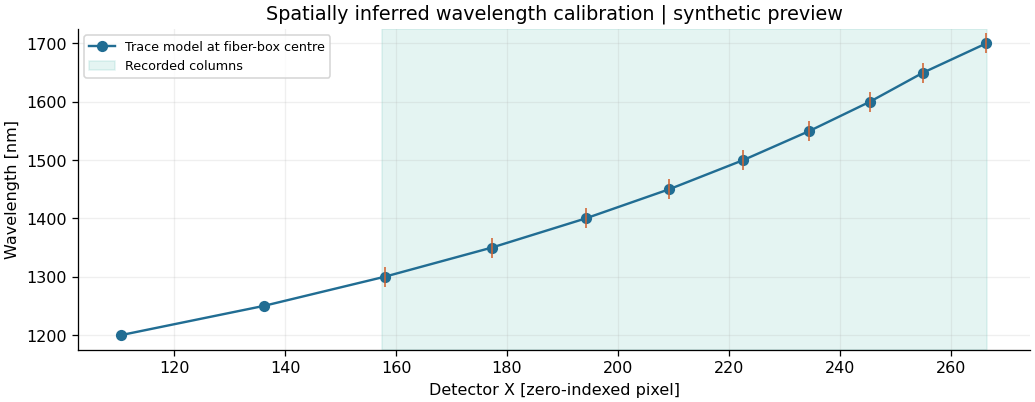

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.5), layout='constrained')
ax.plot(pixel_knots, wavelength_knots, 'o-', color='#216d93', label='Trace model at fiber-box centre')
ax.axvspan(columns[0]-.5, columns[-1]+.5, color='#26a69a', alpha=.12, label='Recorded columns')
for edge in BIN_EDGES_NM:
    if wavelength_knots[0] <= edge <= wavelength_knots[-1]:
        px = np.interp(edge, wavelength_knots, pixel_knots)
        ax.plot(px, edge, '|', ms=12, color='#d26332')
ax.set(xlabel='Detector X [zero-indexed pixel]', ylabel='Wavelength [nm]',
       title='Spatially inferred wavelength calibration' + (' | synthetic preview' if data['demo'] else ''))
ax.legend(loc='upper left', fontsize=8)
ax.grid(alpha=.2)
plt.show()


## Integrated pupil at every Z

All Z panels share one colour scale in ADU/frame, selected by `COLOR_SCALE`. X runs horizontally and Y vertically;
`map.T` converts the saved `[X,Y]` indexing to plotting order. Grey means unacquired or invalid; in log mode, zero/negative flux is also grey.
The turquoise cross marks the brightest sampled point (no subpixel fit). Long Z scans are split over pages.

All pupil images use Voltage and the selected `INTERPOLATION`; grey regions remain masked.


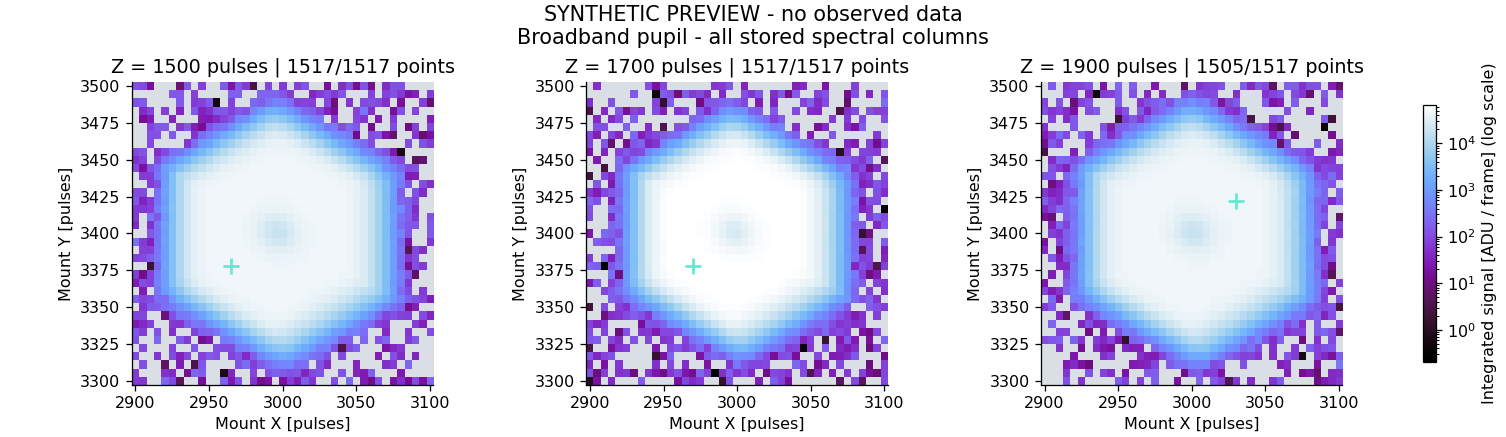

In [10]:
def coordinate_edges(axis):
    if len(axis) == 1:
        return np.array([axis[0] - .5, axis[0] + .5])  # display width only
    mid = (axis[:-1] + axis[1:]) / 2
    return np.r_[axis[0] - (mid[0]-axis[0]), mid, axis[-1] + (axis[-1]-mid[-1])]


def pupil_display_values(values):
    # A view for plotting only: the acquired/integrated arrays are never changed.
    masked = np.ma.masked_invalid(np.asarray(values, dtype=float))
    return np.ma.masked_less_equal(masked, 0) if COLOR_SCALE == 'log' else masked


def shared_norm(values):
    finite = np.asarray(values)[np.isfinite(values)]
    if COLOR_SCALE == 'log':
        positive = finite[finite > 0]
        if not positive.size:
            warnings.warn('No positive flux in this group: log-scale pupil maps will be grey.')
            return LogNorm(vmin=1., vmax=10.)  # valid colourbar; no invented data
        lo, hi = float(positive.min()), float(positive.max())
        if hi == lo:
            lo, hi = lo / 2., hi * 2.
        return LogNorm(vmin=lo, vmax=hi)
    if not finite.size:
        return Normalize(0, 1)
    lo, hi = min(0., float(finite.min())), float(finite.max())
    return Normalize(lo, hi if hi > lo else lo + 1.)


def flux_colorbar_label(label):
    return f'{label} ({COLOR_SCALE} scale)'


def draw_pupil(ax, values, title, norm, mark_peak=False):
    # Acquisition grids are regular. imshow offers nearest/bilinear display interpolation
    # while extent retains the mount-pulse coordinates and saved [X,Y] orientation.
    for axis in (x, y):
        if len(axis) > 2 and not np.allclose(np.diff(axis), np.diff(axis)[0], rtol=1e-7, atol=1e-9):
            raise ValueError('Nearest/bilinear image display requires a uniformly spaced X/Y scan grid.')
    xe, ye = coordinate_edges(x), coordinate_edges(y)
    image = ax.imshow(pupil_display_values(values.T), origin='lower',
                      extent=(xe[0], xe[-1], ye[0], ye[-1]), aspect='equal',
                      cmap=CMAP, norm=norm, interpolation=INTERPOLATION,
                      interpolation_stage='data')
    if mark_peak and np.isfinite(values).any():
        ix, iy = np.unravel_index(np.nanargmax(values), values.shape)
        ax.plot(x[ix], y[iy], '+', color='#5eead4', ms=10, mew=1.7)
    ax.set(title=title, xlabel='Mount X [pulses]', ylabel='Mount Y [pulses]', aspect='equal')
    ax.ticklabel_format(useOffset=False, style='plain')
    return image

broadband_norm = shared_norm(integrated[:, :, z_indices])
for start in range(0, len(z_indices), PANELS_PER_PAGE):
    page = z_indices[start:start+PANELS_PER_PAGE]
    ncols = min(3, len(page))
    nrows = int(np.ceil(len(page) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.1*ncols+0.8, 3.8*nrows),
                             squeeze=False, layout='constrained')
    active_axes = []
    for ax, iz in zip(axes.flat, page):
        count = np.count_nonzero(data['valid'][:, :, iz])
        image = draw_pupil(ax, integrated[:, :, iz],
                           f'Z = {z[iz]:g} pulses | {count}/{len(x)*len(y)} points', broadband_norm, True)
        active_axes.append(ax)
    for ax in list(axes.flat)[len(page):]:
        ax.set_visible(False)
    fig.colorbar(image, ax=active_axes, shrink=.85, label=flux_colorbar_label('Integrated signal [ADU / frame]'))
    fig.suptitle(data['label'] + '\nBroadband pupil - all stored spectral columns', fontsize=13)
    plt.show()


## Spectral pupil: eight 50 nm bins at each Z

Every bin at every selected Z shares the **same absolute colour scale** (`log` or `linear`), so brightness can be compared.
Differences include source spectrum, throughput and wavelength-dependent pupil coupling. These plots
are not independently normalised. Bin-edge fractions are included; incomplete coverage is labelled.


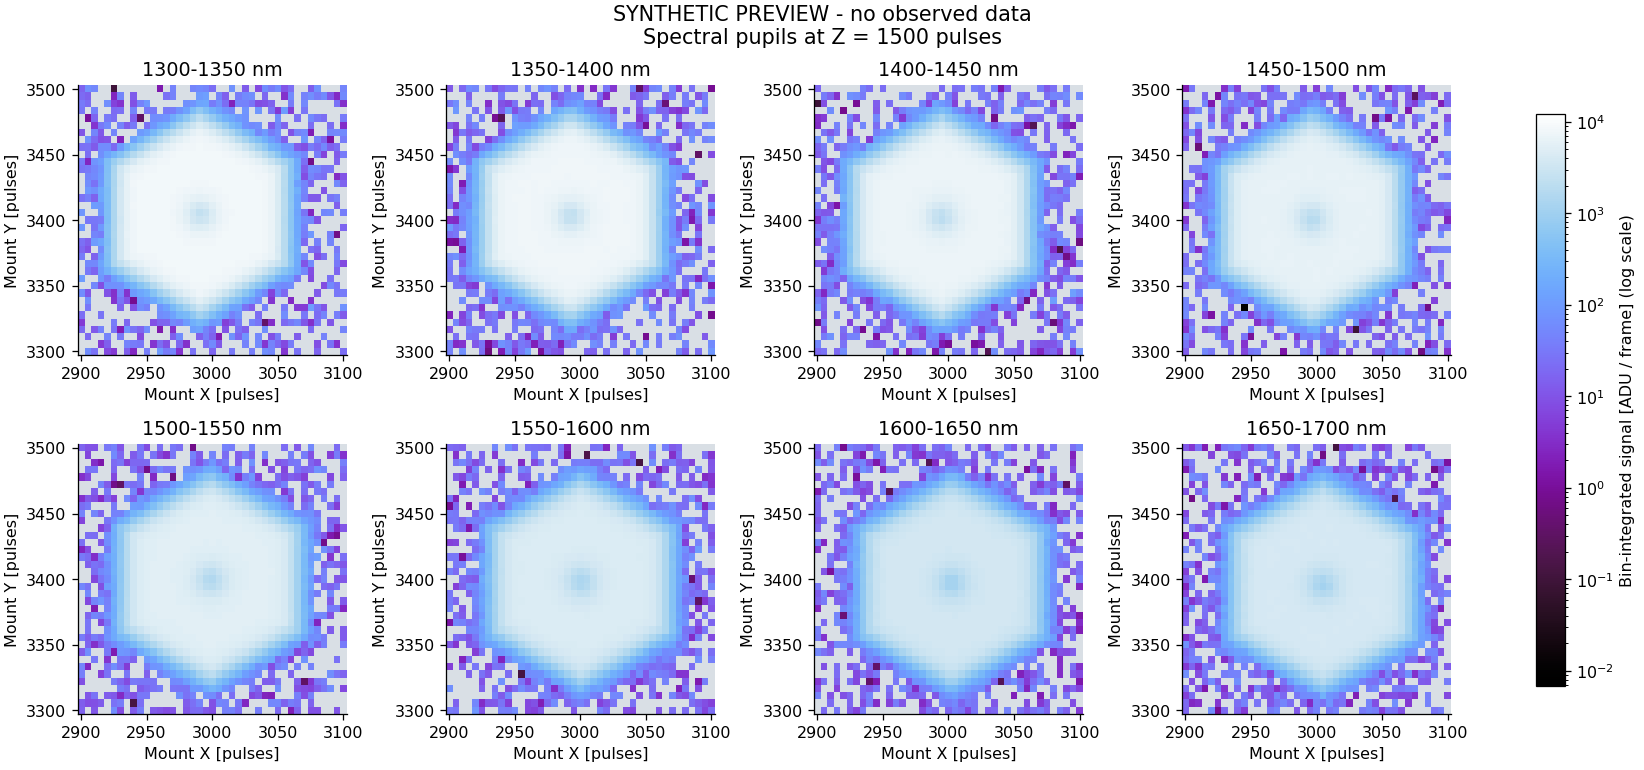

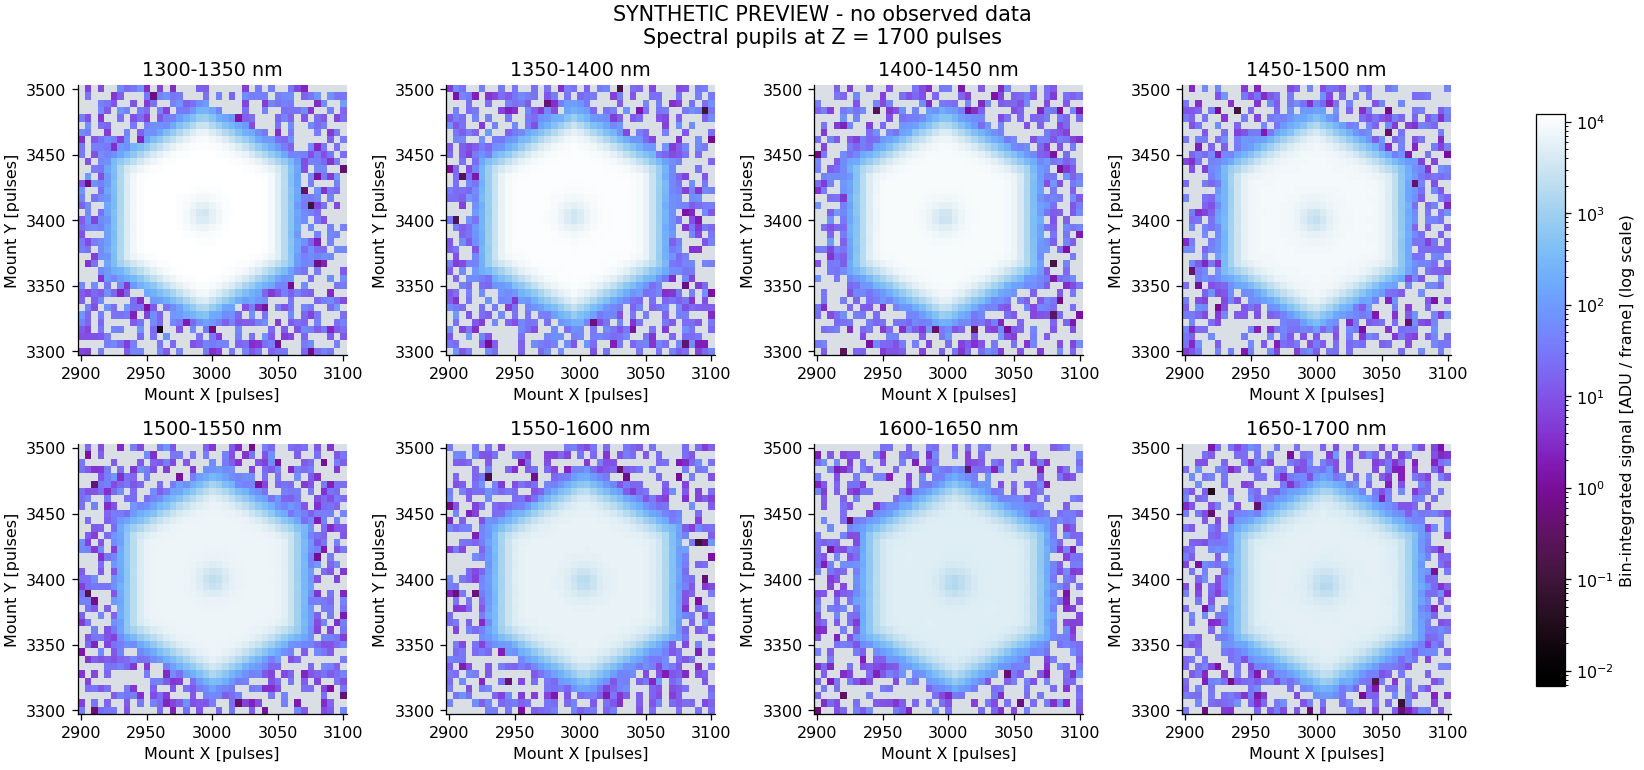

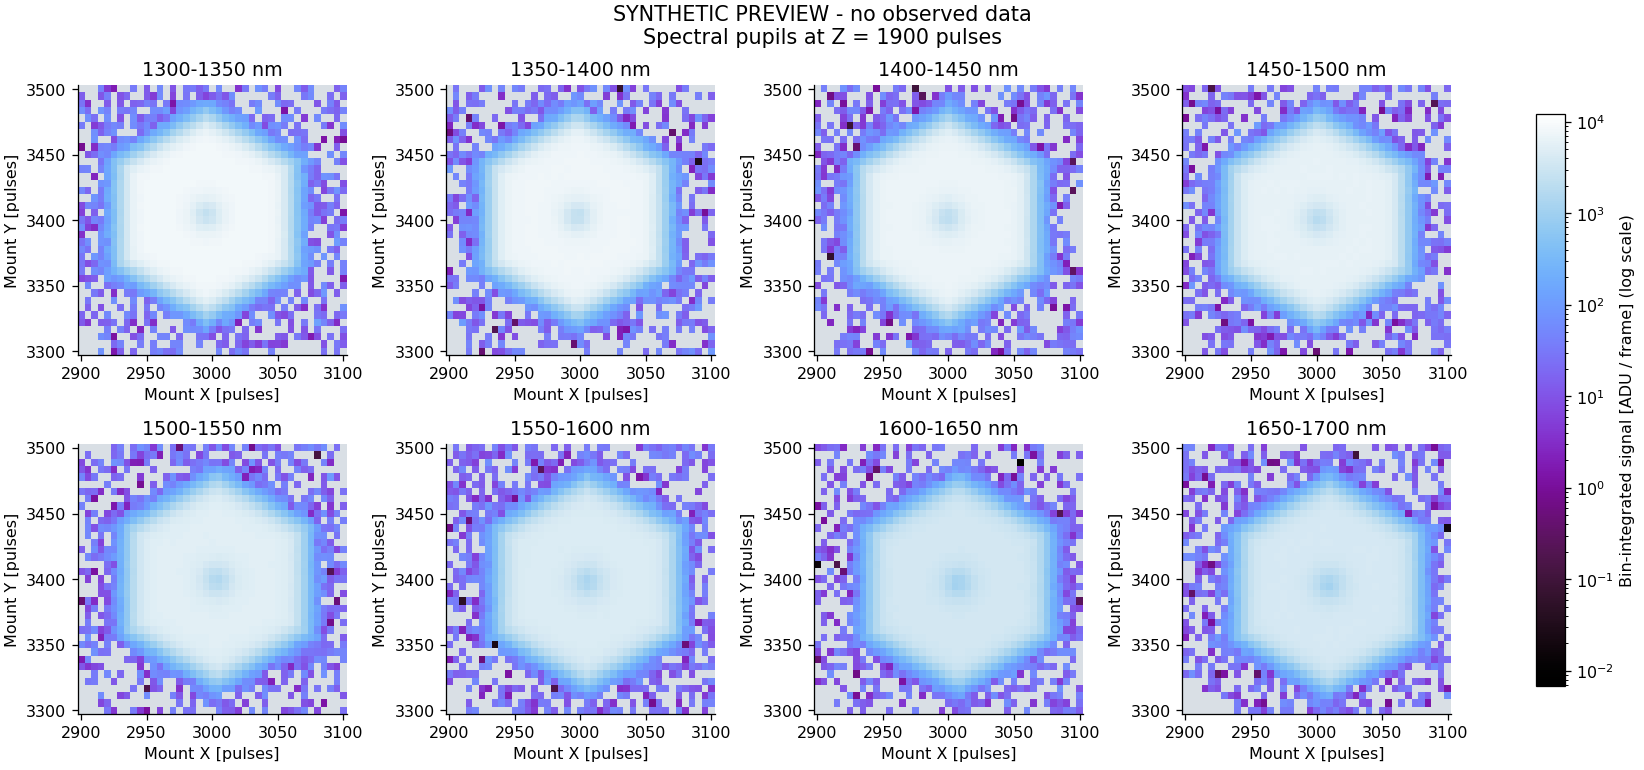

In [11]:
spectral_norm = shared_norm(binned[:, :, z_indices, :])
for iz in z_indices:
    nbins = len(BIN_EDGES_NM) - 1
    ncols = min(4, nbins)
    nrows = int(np.ceil(nbins / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4*ncols+0.7, 3.1*nrows+0.5),
                             squeeze=False, layout='constrained')
    active_axes = []
    for i, ax in enumerate(list(axes.flat)[:nbins]):
        lo, hi = BIN_EDGES_NM[i:i+2]
        note = '' if np.isclose(coverage_nm[i], hi-lo) else f'\nPARTIAL: {coverage_nm[i]:.1f}/{hi-lo:g} nm'
        if coverage_nm[i] == 0:
            note = '\nNO COVERAGE'
        image = draw_pupil(ax, binned[:, :, iz, i], f'{lo:.0f}-{hi:.0f} nm' + note, spectral_norm)
        active_axes.append(ax)
    for ax in list(axes.flat)[nbins:]:
        ax.set_visible(False)
    fig.colorbar(image, ax=active_axes, shrink=.85, label=flux_colorbar_label('Bin-integrated signal [ADU / frame]'))
    fig.suptitle(data['label'] + f'\nSpectral pupils at Z = {z[iz]:g} pulses', fontsize=13)
    plt.show()


## MP4 animation of the spectral pupils

Each frame shows the same eight 50 nm maps, advancing through the selected **Z positions**.
The colour scale stays fixed across all bins and Z planes. Each plane is held for
`MP4_SECONDS_PER_Z`; frames are not interpolated. A single Z plane gives a static hold.

Set `EXPORT_MP4=False` to skip. With `MP4_PATH=None`, observations save
`<cube_stem>_spectral_pupils.mp4` alongside the cube; demo mode saves
`fiber_focus_spectral_preview.mp4` beside this notebook. An existing movie at that path is
replaced when this cell runs. The movie is also embedded below for playback. Input data and
calibration are unchanged. Set `MP4_PATH` to choose another existing writable folder.

An H.264 encoder is required: either system `ffmpeg` or the binary bundled with
`imageio-ffmpeg`. If needed, install in this kernel environment with `%pip install imageio-ffmpeg`.

The movie uses the same Voltage colormap, `INTERPOLATION`, and `COLOR_SCALE` as the static pupil maps.
Log mode masks nonpositive pixels in every frame.


In [12]:
from matplotlib.animation import FFMpegWriter
from IPython.display import Video, display
import shutil


def spectral_animation_path(data, selected_path, override=None):
    if override is not None:
        result = Path(override).expanduser()
    elif not data['demo']:
        result = Path(selected_path).with_name(Path(selected_path).stem + '_spectral_pupils.mp4')
    else:
        # Jupyter can launch in either the repository root or the notebook folder.
        directory = Path.cwd()
        for parent in (Path.cwd(), *Path.cwd().parents):
            candidates = (parent, parent / 'Matteo' / 'Fiber_focus_scans')
            found = next((d for d in candidates if (d / 'analyse_fiber_focus_scans.ipynb').is_file()), None)
            if found is not None:
                directory = found
                break
        result = directory / 'fiber_focus_spectral_preview.mp4'
    if result.suffix.lower() != '.mp4':
        raise ValueError('MP4_PATH must end in .mp4.')
    return result.resolve()


def save_spectral_animation(path, fps=8, seconds_per_z=1.25):
    if not isinstance(fps, (int, np.integer)) or fps <= 0 or not np.isfinite(seconds_per_z) or seconds_per_z <= 0:
        raise ValueError('MP4_FPS must be a positive integer and MP4_SECONDS_PER_Z must be positive.')
    encoder = shutil.which('ffmpeg')
    if encoder is None:
        try:
            import imageio_ffmpeg
            encoder = imageio_ffmpeg.get_ffmpeg_exe()
        except (ImportError, RuntimeError) as error:
            raise RuntimeError('MP4 export needs ffmpeg. Install imageio-ffmpeg in this kernel environment, '
                               'or set EXPORT_MP4=False for static analysis.') from error
    path = Path(path)
    if not path.parent.is_dir():
        raise FileNotFoundError(f'Animation destination folder does not exist: {path.parent}')
    nbins = len(BIN_EDGES_NM) - 1
    ncols = min(4, nbins)
    nrows = int(np.ceil(nbins / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 7), squeeze=False)
    # Fixed geometry prevents axes/colorbar movement between frames.
    fig.subplots_adjust(left=.065, right=.88, bottom=.09, top=.83, wspace=.37, hspace=.42)
    artists = []
    for i, ax in enumerate(list(axes.flat)[:nbins]):
        lo, hi = BIN_EDGES_NM[i:i+2]
        note = '' if np.isclose(coverage_nm[i], hi-lo) else chr(10) + f'PARTIAL: {coverage_nm[i]:.1f}/{hi-lo:g} nm'
        if coverage_nm[i] == 0:
            note = chr(10) + 'NO COVERAGE'
        image = draw_pupil(ax, binned[:, :, z_indices[0], i], f'{lo:.0f}-{hi:.0f} nm' + note, spectral_norm)
        artists.append(image)
    for ax in list(axes.flat)[nbins:]:
        ax.set_visible(False)
    colorbar_ax = fig.add_axes([.91, .14, .014, .63])
    fig.colorbar(artists[0], cax=colorbar_ax, label=flux_colorbar_label('Bin-integrated signal [ADU / frame]'))
    heading = fig.suptitle('', fontsize=13, y=.97)
    frames_per_z = max(1, int(round(fps * seconds_per_z)))
    writer = FFMpegWriter(fps=int(fps), codec='libx264', bitrate=2200,
                         extra_args=['-pix_fmt', 'yuv420p', '-movflags', '+faststart'],
                         metadata={'title': 'Fiber focus - spectral pupils', 'comment': data['label']})
    try:
        with plt.rc_context({'animation.ffmpeg_path': encoder}):
            with writer.saving(fig, str(path), dpi=100):
                for frame, iz in enumerate(z_indices):
                    for i, artist in enumerate(artists):
                        artist.set_data(pupil_display_values(binned[:, :, iz, i].T))
                    count = int(data['valid'][:, :, iz].sum())
                    heading.set_text(data['label'] + chr(10) + f'Z = {z[iz]:g} pulses | plane {frame+1}/{len(z_indices)}'
                                     f' | {count}/{len(x)*len(y)} valid points | {COLOR_SCALE} scale')
                    for _ in range(frames_per_z):
                        writer.grab_frame(facecolor='white')
    finally:
        plt.close(fig)
    return {'path': path, 'frames': len(z_indices)*frames_per_z,
            'fps': int(fps), 'duration_s': len(z_indices)*frames_per_z/fps}


if EXPORT_MP4:
    animation_path = spectral_animation_path(data, selected_data_path, MP4_PATH)
    animation_info = save_spectral_animation(animation_path, MP4_FPS, MP4_SECONDS_PER_Z)
    print(f'Saved {animation_info["frames"]} frames, {animation_info["duration_s"]:.2f} s: {animation_path}')
    display(Video(filename=str(animation_path), embed=True,
                  html_attributes='controls loop muted playsinline', width=1000))
else:
    print('MP4 export skipped (EXPORT_MP4=False).')


Saved 30 frames, 3.75 s: C:\Users\mcol0021\OneDrive - The University of Sydney (Staff)\Documents\GitHub\GLINT\Matteo\Fiber_focus_scans\fiber_focus_spectral_preview.mp4


<Voltage spectral-pupil MP4: log scale>

## Spectrum and focus diagnostics

The spectrum is taken at the globally brightest valid broadband X/Y/Z sample. Its vertical axis is
row-summed signal **per detector column**, so it is not a spectral density per nm. The focus diagnostic
reports the maximum sampled broadband flux in each Z plane. Missing points can bias this maximum;
the acquired counts are printed below. With one Z plane, it is a single sample, not a focus estimate.
No fit or focus recommendation is made without measured scan coverage.

`COLOR_SCALE` controls both diagnostic Y axes. Log mode omits nonpositive samples from these lines.


Z [pulses]  valid XY points  peak signal [ADU/frame]
      1500   1517/1517       47548.3
      1700   1517/1517       67279.7
      1900   1505/1517       47580.5


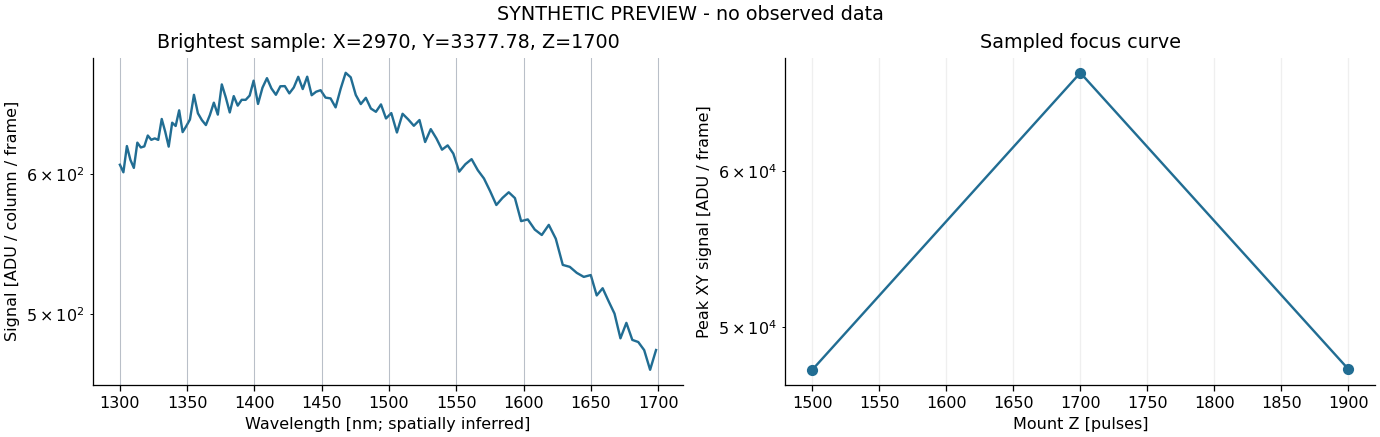

In [13]:
ix, iy, iz_best = np.unravel_index(np.nanargmax(integrated), integrated.shape)
lam_centres = np.interp(columns, pixel_knots, wavelength_knots, left=np.nan, right=np.nan)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout='constrained')
axes[0].plot(lam_centres, pupil_display_values(height * data['spectra'][ix, iy, iz_best]), color='#216d93', lw=1.5)
for edge in BIN_EDGES_NM:
    axes[0].axvline(edge, color='#64748b', lw=.6, alpha=.4)
axes[0].set(xlabel='Wavelength [nm; spatially inferred]', ylabel='Signal [ADU / column / frame]',
            title=f'Brightest sample: X={x[ix]:g}, Y={y[iy]:g}, Z={z[iz_best]:g}')
peak_by_z = np.array([np.nanmax(integrated[:, :, k]) if np.isfinite(integrated[:, :, k]).any()
                      else np.nan for k in range(len(z))])
axes[1].plot(z, pupil_display_values(peak_by_z), 'o-', color='#216d93')
axes[1].set(xlabel='Mount Z [pulses]', ylabel='Peak XY signal [ADU / frame]',
            title='Sampled focus curve' if len(z)>1 else 'Single Z sample - no focus scan')
for ax in axes:
    ax.set_yscale(COLOR_SCALE)
    ax.grid(alpha=.2)
    ax.ticklabel_format(axis='x', useOffset=False, style='plain')
fig.suptitle(data['label'], fontsize=12)
plt.show()
print('Z [pulses]  valid XY points  peak signal [ADU/frame]')
for k, zz in enumerate(z):
    print(f'{zz:10g}  {data["valid"][:, :, k].sum():5d}/{len(x)*len(y):<5d}      {peak_by_z[k]:.6g}')


## Interpretation and use with real cubes

- Set `USE_DEMO_DATA=False`, optionally select `DATA_PATH`, and **Run All**. All Z planes are shown unless you set `Z_INDICES`.
- The original cube and calibration remain untouched. Results are held in `integrated[X,Y,Z]` and `binned[X,Y,Z,bin]`.
- The embedded calibration is a snapshot of the supplied solution. To refresh it at runtime, set `CALIBRATION_PATH`.
- The port-8 wavelengths are inferred from the detector trace surface. Check monochromatic fiber exposures if
  precise bin assignment is required; the model's small residuals on its measured channels do not establish a
  direct port-8 uncertainty or exclude instrument drift.
- The calibration report identifies an electronic ghost displaced towards larger detector X. These maps use the
  saved observed signal and do not deghost it. Raw detector frames and row-resolved information were not saved
  by this scan, so bad-pixel masking or changing the extraction box cannot be redone here.
- Integrated flux covers the recorded box only; light outside the box cannot be recovered. Linear scales retain
  negative dark-subtraction residuals. Log scales mask nonpositive values for display only; the arrays
  retain the original measurements. An all-nonpositive map is grey. A singleton X or Y is drawn
  with an arbitrary one-pulse cell width.

**Preview status:** synthetic data only. The preview is a check of the notebook's calculations and layout,
not evidence about the instrument's pupil, spectral response, or best focus.


<details>
<summary>CMasher Voltage attribution and BSD 3-Clause license</summary>

The embedded table is from [CMasher Voltage](https://cmasher.readthedocs.io/user/sequential/voltage.html).
Source RGB table SHA256: `060b988377358094827be2aa4bae17622922215c92429aa8a9f6657346cd4db0`.

```text
BSD 3-Clause License

Copyright (c) 2019-2021, Ellert van der Velden
All rights reserved.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

* Redistributions of source code must retain the above copyright notice, this
  list of conditions and the following disclaimer.
* Redistributions in binary form must reproduce the above copyright notice,
  this list of conditions and the following disclaimer in the documentation
  and/or other materials provided with the distribution.
* Neither the name of the copyright holder nor the names of its
  contributors may be used to endorse or promote products derived from
  this software without specific prior written permission.

THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS AND CONTRIBUTORS "AS IS"
AND ANY EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR PURPOSE ARE
DISCLAIMED. IN NO EVENT SHALL THE COPYRIGHT HOLDER OR CONTRIBUTORS BE LIABLE
FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL, EXEMPLARY, OR CONSEQUENTIAL
DAMAGES (INCLUDING, BUT NOT LIMITED TO, PROCUREMENT OF SUBSTITUTE GOODS OR
SERVICES; LOSS OF USE, DATA, OR PROFITS; OR BUSINESS INTERRUPTION) HOWEVER
CAUSED AND ON ANY THEORY OF LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY,
OR TORT (INCLUDING NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE
OF THIS SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
```
</details>
